# Option 3: Support Vector Machine, Version 2
Yang Xiao (yx752)

## Step 0: Imports and Data
This experiment tests whether adding writing-style and character features improves the original word TF-IDF SVM. Dependencies: numpy, pandas, scipy, scikit-learn and matplotlib. Run the cells in order; the final cell writes the selected candidate CSV.

In [1]:
from pathlib import Path
from functools import lru_cache
import re
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, hstack
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.svm import LinearSVC, SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import roc_auc_score

SEED = 27
data_candidates = [Path('data'), Path('.'),
                   Path('../cornell-tech-cs-5785-combined-2026-ai-vs-human-text')]
DATA = next((p for p in data_candidates if (p / 'train.csv').exists()), None)
if DATA is None:
    raise FileNotFoundError('Place the competition CSV files in data/ beside this notebook.')
OUT = Path('svm_v2_results')
OUT.mkdir(exist_ok=True)
train = pd.read_csv(DATA / 'train.csv')
test = pd.read_csv(DATA / 'test.csv')
sample = pd.read_csv(DATA / 'sample_submission.csv')
assert train.id.is_unique and test.id.is_unique
assert not train[['text', 'label']].isna().any().any()
tr, va = train_test_split(np.arange(len(train)), test_size=2000,
                         stratify=train.label, random_state=SEED)
x, y = train.text.iloc[tr], train.label.iloc[tr]
xv, yv = train.text.iloc[va], train.label.iloc[va]
assert len(tr) == 8000 and len(va) == 2000
assert yv.value_counts().to_dict() == {0: 1000, 1: 1000}
train.iloc[va][['id']].to_csv(OUT / 'val_ids.csv', index=False)
print('Train:', len(x), '| Validation:', len(xv), '| Split seed:', SEED)

Train: 8000 | Validation: 2000 | Split seed: 27


## Step 1: Style Features
The feature function measures lexical diversity, repetition, sentence and paragraph structure, punctuation, and several phrase frequencies. The function sees only the text. Cached raw features are deterministic; standardization is fitted separately within each training fold.

In [2]:
def extract_style_features(text):
    """Return measurable lexical, structural, repetition, and punctuation signals."""
    text = str(text)
    words = re.findall(r"\b[\w']+\b", text.lower())
    word_count = max(len(words), 1)
    sentences = [s for s in re.split(r"(?<=[.!?])\s+|\n+", text.strip()) if s.strip()]
    paragraphs = [p for p in re.split(r"\n\s*\n", text.strip()) if p.strip()]
    sentence_lengths = [len(re.findall(r"\b[\w']+\b", s)) for s in sentences]
    paragraph_lengths = [len(re.findall(r"\b[\w']+\b", p)) for p in paragraphs]
    word_counts = pd.Series(words).value_counts()
    bigrams = list(zip(words, words[1:]))
    bigram_counts = pd.Series(bigrams).value_counts() if bigrams else pd.Series(dtype=int)
    normalized = text.lower()

    def repeat_fraction(counts, total):
        if total == 0 or len(counts) == 0:
            return 0.0
        return float((counts - 1).clip(lower=0).sum() / total)

    def mean(values):
        return float(np.mean(values)) if values else 0.0

    def std(values):
        return float(np.std(values)) if len(values) > 1 else 0.0

    # Candidate discourse templates; counts are normalized per 1,000 words below.
    template_patterns = {
        "not_just_but": r"\bnot just\b.{0,160}\bbut\b",
        "not_only_but_also": r"\bnot only\b.{0,160}\bbut also\b",
        "in_conclusion": r"\bin conclusion\b",
        "it_is_important_to_note": r"\bit is important to note\b",
        "moreover": r"\bmoreover\b",
        "furthermore": r"\bfurthermore\b",
    }
    features = {
        "log_word_count": np.log1p(len(words)),  # Log-scaled number of words.
        "log_character_count": np.log1p(len(text)),  # Log-scaled number of characters, including whitespace.
        "mean_word_length": mean([len(w) for w in words]),  # Average characters per token.
        "word_length_std": std([len(w) for w in words]),  # Variation in token lengths.
        "type_token_ratio": len(set(words)) / word_count,  # Unique words divided by total words; rough lexical diversity.
        "repeated_word_fraction": repeat_fraction(word_counts, len(words)),  # Fraction of word tokens beyond each word's first occurrence.
        "repeated_bigram_fraction": repeat_fraction(bigram_counts, len(bigrams)),  # Fraction of adjacent word-pairs beyond each pair's first occurrence.
        "sentence_count": np.log1p(len(sentences)),  # Log-scaled count of sentence-like spans.
        "mean_sentence_length": mean(sentence_lengths),  # Average words per sentence-like span.
        "sentence_length_std": std(sentence_lengths),  # Spread of sentence lengths.
        "sentence_length_cv": std(sentence_lengths) / max(mean(sentence_lengths), 1.0),  # Sentence-length spread relative to its mean.
        "paragraph_count": np.log1p(len(paragraphs)),  # Log-scaled count of blocks separated by blank lines.
        "mean_paragraph_length": mean(paragraph_lengths),  # Average words per paragraph block.
        "paragraph_length_std": std(paragraph_lengths),  # Spread of paragraph word counts.
        "repeated_sentence_fraction": (len(sentences) - len(set(s.strip().lower() for s in sentences))) / max(len(sentences), 1),  # Share of sentence-like spans duplicated after lowercasing.
        "exclamation_per_100_words": 100 * text.count("!") / word_count,  # Exclamation marks per 100 words.
        "question_per_100_words": 100 * text.count("?") / word_count,  # Question marks per 100 words.
        "comma_per_100_words": 100 * text.count(",") / word_count,  # Commas per 100 words.
        "semicolon_per_100_words": 100 * text.count(";") / word_count,  # Semicolons per 100 words.
        "colon_per_100_words": 100 * text.count(":") / word_count,  # Colons per 100 words.
        "dash_per_100_words": 100 * (text.count("—") + text.count("–")) / word_count,  # Em/en dashes per 100 words.
        "ellipsis_per_100_words": 100 * (text.count("...") + text.count("…")) / word_count,  # Three-dot or single-character ellipses per 100 words.
        "digit_character_fraction": sum(ch.isdigit() for ch in text) / max(len(text), 1),  # Fraction of all characters that are digits.
        "uppercase_character_fraction": sum(ch.isupper() for ch in text) / max(sum(ch.isalpha() for ch in text), 1),  # Fraction of letters that are uppercase.
        "contraction_per_100_words": 100 * len(re.findall(r"\b\w+['’](?:t|re|ve|ll|d|m)\b", normalized)) / word_count,  # Common English contractions per 100 words.
    }
    for name, pattern in template_patterns.items():
        # Frequency of each hypothesized phrase pattern per 1,000 words.
        features[f"template_{name}_per_1000_words"] = 1000 * len(re.findall(pattern, normalized, flags=re.DOTALL)) / word_count
    return features

@lru_cache(maxsize=20000)
def cached_style(text):
    return tuple(extract_style_features(text).values())

def style_matrix(texts):
    return np.asarray([cached_style(str(text)) for text in texts], dtype=float)

style_names = list(extract_style_features('').keys())
print('Style features:', len(style_names))
print(', '.join(style_names))

Style features: 31
log_word_count, log_character_count, mean_word_length, word_length_std, type_token_ratio, repeated_word_fraction, repeated_bigram_fraction, sentence_count, mean_sentence_length, sentence_length_std, sentence_length_cv, paragraph_count, mean_paragraph_length, paragraph_length_std, repeated_sentence_fraction, exclamation_per_100_words, question_per_100_words, comma_per_100_words, semicolon_per_100_words, colon_per_100_words, dash_per_100_words, ellipsis_per_100_words, digit_character_fraction, uppercase_character_fraction, contraction_per_100_words, template_not_just_but_per_1000_words, template_not_only_but_also_per_1000_words, template_in_conclusion_per_1000_words, template_it_is_important_to_note_per_1000_words, template_moreover_per_1000_words, template_furthermore_per_1000_words


## Step 2: Feature and Model Definitions
The word baseline keeps its original unigram/bigram settings. Character features use within-word 3–5-grams. For combined linear models, a weight controls the contribution of standardized style features relative to L2-normalized TF-IDF. I also test an RBF SVM on style features to allow nonlinear relations without applying a kernel to the large text feature matrix.

In [3]:
def word_features():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                           max_features=100000, sublinear_tf=True)

def char_features():
    return TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3,
                           max_features=100000, sublinear_tf=True)

def style_features():
    return Pipeline([('raw', FunctionTransformer(style_matrix, validate=False)),
                     ('scale', StandardScaler())])

def make_model(config):
    kind = config['kind']
    C = float(config['C'])
    if kind == 'style_rbf':
        return Pipeline([('features', style_features()),
                         ('svm', SVC(C=C, gamma=config['gamma'], kernel='rbf', cache_size=512))])
    blocks = []
    if kind in ['word', 'word_style', 'word_char_style']:
        blocks.append(('word', word_features()))
    if kind == 'word_char_style':
        blocks.append(('char', char_features()))
    if kind != 'word':
        blocks.append(('style', style_features()))
    weights = {'word': 1.0, 'char': 1.0, 'style': float(config.get('style_weight', 1.0))}
    features = FeatureUnion(blocks, transformer_weights={name: weights[name] for name, _ in blocks})
    return Pipeline([('features', features),
                     ('svm', LinearSVC(C=C, dual='auto', max_iter=30000, random_state=SEED))])

## Step 3: Controlled Feature Comparisons
All candidates use the same 8,000/2,000 partition. Candidate values are fixed before running: linear C in {0.1, 1, 10}; style weights in {0.1, 0.3, 1}; style RBF C in {1, 10, 100} with gamma in {scale, 0.03}. Runtime includes feature fitting and classifier training but excludes evaluation. Feature representations are cached across settings for this search only.

In [4]:
feature_cache = {}
records = []
configs = [{'kind': 'word', 'C': 1.0}]
configs += [{'kind': 'style_linear', 'C': C, 'style_weight': 1.0} for C in [0.1, 1, 10]]
configs += [{'kind': 'style_rbf', 'C': C, 'gamma': gamma}
            for C in [1, 10, 100] for gamma in ['scale', 0.03]]
configs += [{'kind': kind, 'C': C, 'style_weight': weight}
            for kind in ['word_style', 'word_char_style']
            for C in [0.1, 1, 10] for weight in [0.1, 0.3, 1.0]]
for index, config in enumerate(configs):
    model = make_model(config)
    feature_key = (config['kind'], config.get('style_weight', 1.0))
    if config['kind'] == 'style_rbf':
        feature_key = ('style_linear', 1.0)
    if feature_key not in feature_cache:
        start = time.perf_counter()
        features = model.named_steps['features']
        z = features.fit_transform(x, y)
        feature_seconds = time.perf_counter() - start
        zv = features.transform(xv)
        feature_cache[feature_key] = (z, zv, feature_seconds)
    z, zv, feature_seconds = feature_cache[feature_key]
    start = time.perf_counter()
    classifier = model.named_steps['svm'].fit(z, y)
    seconds = feature_seconds + time.perf_counter() - start
    row = {'candidate': index, **config,
           'train_auroc': roc_auc_score(y, classifier.decision_function(z)),
           'val_auroc': roc_auc_score(yv, classifier.decision_function(zv)),
           'train_seconds': seconds}
    records.append(row)
    print(f"{index:2d} {config}: val={row['val_auroc']:.6f}", flush=True)
search = pd.DataFrame(records).sort_values('val_auroc', ascending=False)
search.to_csv(OUT / 'search.csv', index=False)
print(search[['candidate', 'kind', 'C', 'style_weight', 'gamma', 'train_auroc', 'val_auroc']].head(12).to_string(index=False))
del feature_cache

 0 {'kind': 'word', 'C': 1.0}: val=0.944737
 1 {'kind': 'style_linear', 'C': 0.1, 'style_weight': 1.0}: val=0.986570
 2 {'kind': 'style_linear', 'C': 1, 'style_weight': 1.0}: val=0.987487
 3 {'kind': 'style_linear', 'C': 10, 'style_weight': 1.0}: val=0.987666
 4 {'kind': 'style_rbf', 'C': 1, 'gamma': 'scale'}: val=0.993870
 5 {'kind': 'style_rbf', 'C': 1, 'gamma': 0.03}: val=0.993778
 6 {'kind': 'style_rbf', 'C': 10, 'gamma': 'scale'}: val=0.994169
 7 {'kind': 'style_rbf', 'C': 10, 'gamma': 0.03}: val=0.994213
 8 {'kind': 'style_rbf', 'C': 100, 'gamma': 'scale'}: val=0.993130
 9 {'kind': 'style_rbf', 'C': 100, 'gamma': 0.03}: val=0.993207
10 {'kind': 'word_style', 'C': 0.1, 'style_weight': 0.1}: val=0.985873
11 {'kind': 'word_style', 'C': 0.1, 'style_weight': 0.3}: val=0.989264
12 {'kind': 'word_style', 'C': 0.1, 'style_weight': 1.0}: val=0.991782
13 {'kind': 'word_style', 'C': 1, 'style_weight': 0.1}: val=0.991943
14 {'kind': 'word_style', 'C': 1, 'style_weight': 0.3}: val=0.993392
15

## Step 4: Stability Check on Training-Only Folds
For each feature family, take the configuration with the highest development AUROC and compute three-fold training-only CV. Every fold refits TF-IDF and style scaling. These checks assess stability of the shortlisted settings; they are not an unbiased nested-CV estimate because the shortlist was chosen using development performance. Select the family winner with the highest mean CV AUROC. Keep the original development partition unchanged.

In [5]:
family_winners = search.groupby('kind', sort=False).head(1)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
cv_rows = []
for candidate in family_winners.candidate.astype(int):
    config = configs[candidate]
    scores = cross_val_score(make_model(config), x, y, cv=cv, scoring='roc_auc', n_jobs=1)
    cv_rows.append({'candidate': candidate, 'kind': config['kind'],
                    'cv_mean': float(scores.mean()), 'cv_std': float(scores.std()),
                    'fold_scores': scores.tolist()})
    print(config, scores, flush=True)
cv_results = pd.DataFrame(cv_rows).sort_values(['cv_mean', 'candidate'], ascending=[False, True])
cv_results.to_csv(OUT / 'cv_check.csv', index=False)
chosen_id = int(cv_results.iloc[0].candidate)
chosen = configs[chosen_id]
print('Chosen configuration:', chosen)
print(cv_results[['kind', 'cv_mean', 'cv_std']].to_string(index=False))

{'kind': 'word_style', 'C': 10, 'style_weight': 1.0} [0.99200887 0.99386241 0.99018791]
{'kind': 'word_char_style', 'C': 10, 'style_weight': 1.0} [0.99216971 0.99422513 0.99047042]
{'kind': 'style_rbf', 'C': 10, 'gamma': 0.03} [0.99085041 0.99191383 0.9898463 ]
{'kind': 'style_linear', 'C': 10, 'style_weight': 1.0} [0.98686328 0.9852077  0.98580046]
{'kind': 'word', 'C': 1.0} [0.93840533 0.93562165 0.93466728]
Chosen configuration: {'kind': 'word_char_style', 'C': 10, 'style_weight': 1.0}
           kind  cv_mean   cv_std
word_char_style 0.992288 0.001535
     word_style 0.992020 0.001500
      style_rbf 0.990870 0.000844
   style_linear 0.985957 0.000685
           word 0.936231 0.001586


## Step 5: Calibrated Validation and Error Analysis
Sigmoid calibration uses three training-only folds of the full feature pipeline. This keeps the vocabulary and style scaler out of the calibration holdout in each fold. Errors use probability threshold 0.5. The reported AUROC remains a development result, not an independent estimate for unfamiliar test domains.

In [6]:
def calibrated_model():
    folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    return CalibratedClassifierCV(make_model(chosen), method='sigmoid',
                                  cv=folds, ensemble=False)

selected = calibrated_model()
start = time.perf_counter()
selected.fit(x, y)
selected_seconds = time.perf_counter() - start
pv = selected.predict_proba(xv)[:, 1]
train_auc = roc_auc_score(y, selected.predict_proba(x)[:, 1])
val_auc = roc_auc_score(yv, pv)
baseline_auc = float(search.loc[search.kind == 'word', 'val_auroc'].iloc[0])
print(f'Baseline validation AUROC: {baseline_auc:.6f}')
print(f'Selected train AUROC: {train_auc:.6f}')
print(f'Selected validation AUROC: {val_auc:.6f}')
print(f'Change: {val_auc - baseline_auc:+.6f}')
validation = pd.DataFrame({'id': train.id.iloc[va].to_numpy(), 'label': yv.to_numpy(),
                           'probability': pv, 'words': xv.str.split().str.len().to_numpy()})
validation['error'] = np.where((validation.label == 0) & (pv >= .5), 'FP',
                              np.where((validation.label == 1) & (pv < .5), 'FN', 'correct'))
validation.to_csv(OUT / 'validation_predictions.csv', index=False)
bins = pd.cut(validation.words, [0, 150, 250, np.inf], labels=['<=150', '151-250', '>250'])
length_rows = [{'length_bin': str(name), 'count': len(group),
                'val_auroc': roc_auc_score(group.label, group.probability)}
               for name, group in validation.groupby(bins, observed=True)]
print(pd.DataFrame(length_rows).to_string(index=False))
errors = pd.concat([validation[validation.error == 'FP'].nlargest(5, 'probability'),
                    validation[validation.error == 'FN'].nsmallest(5, 'probability')])
print(errors[['id', 'error', 'probability', 'words']].to_string(index=False))
errors.to_csv(OUT / 'errors.csv', index=False)
summary = {'seed': SEED, 'chosen': chosen, 'train_auroc': train_auc, 'val_auroc': val_auc,
           'baseline_val_auroc': baseline_auc, 'train_seconds_including_calibration': selected_seconds}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2))

Baseline validation AUROC: 0.944737
Selected train AUROC: 1.000000
Selected validation AUROC: 0.995193
Change: +0.050456
length_bin  count  val_auroc
     <=150    403   0.987410
   151-250   1036   0.996716
      >250    561   0.995354
  id error  probability  words
4468    FP     0.969362     77
 855    FP     0.910289    142
9647    FP     0.867374    191
9039    FP     0.814381    152
3944    FP     0.806355    132
2581    FN     0.002726    269
5893    FN     0.009590    196
6997    FN     0.017513    163
1614    FN     0.019945    115
8444    FN     0.025179    327


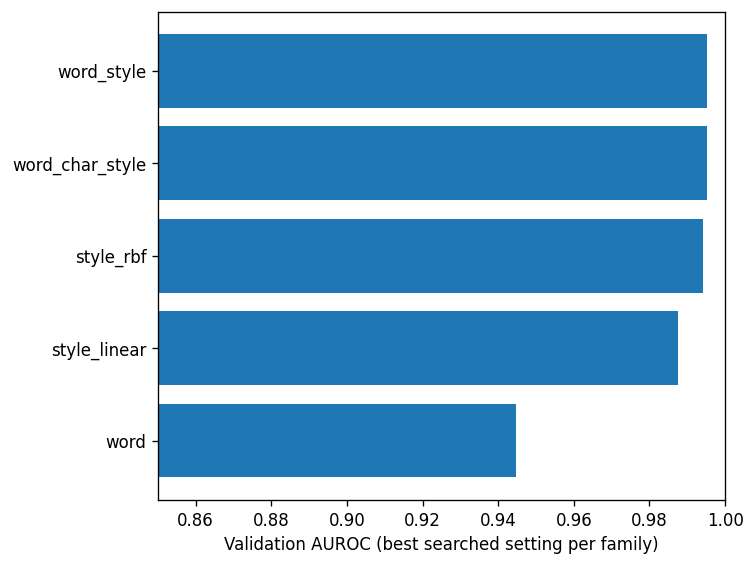

In [7]:
best_by_family = search.groupby('kind', sort=False).head(1).sort_values('val_auroc')
plt.barh(best_by_family.kind, best_by_family.val_auroc)
plt.xlim(0.85, 1.0)
plt.xlabel('Validation AUROC (best searched setting per family)')
plt.tight_layout()
plt.show()

## Step 6: Full-Data Refit and Submission
Refit the selected calibrated pipeline using all 10,000 supplied labeled rows. Neither test labels nor external labeled data are used. The model is chosen before predicting test text. The CSV uses the sample submission ID order.

In [8]:
final_model = calibrated_model()
final_model.fit(train.text, train.label)
submission = pd.DataFrame({'id': test.id, 'label': final_model.predict_proba(test.text)[:, 1]})
submission = submission.set_index('id').loc[sample.id].reset_index()
assert list(submission.columns) == ['id', 'label']
assert len(submission) == 3000 and submission.id.is_unique
assert submission.id.tolist() == sample.id.tolist()
assert set(submission.id) == set(test.id)
assert submission.label.between(0, 1).all() and np.isfinite(submission.label).all()
submission.to_csv(OUT / 'submission_svm_yx752_v2.csv', index=False)
print('Saved 3,000 probability predictions to svm_v2_results/submission_svm_yx752_v2.csv')

Saved 3,000 probability predictions to svm_v2_results/submission_svm_yx752_v2.csv


## Results
The original word TF-IDF model has development AUROC 0.944737. Adding style features gives 0.995211 at the best searched setting; adding character features as well gives 0.995193. Training-only three-fold checks favor the word/character/style model, with mean AUROC 0.992288 versus 0.992020 for word/style and 0.936231 for the baseline. The small difference between the two combined models does not establish a reliable character-feature advantage.

The selected configuration is word unigram/bigram TF-IDF plus within-word character 3–5-grams and 31 standardized style features, using LinearSVC with C=10 and style weight 1. Sigmoid calibration retains development AUROC 0.995193. At threshold 0.5, there are 15 false positives and 37 false negatives among 2,000 development rows. The largest improvement comes from including style information. Test generalization must be assessed separately; these development results do not establish a Kaggle score.

A higher development score does not guarantee a higher private score. The search and family shortlist reuse one development split, and phrase features may be specific to the supplied generators. The earlier word-only SVM achieved 0.85289 public AUROC despite 0.944737 development AUROC; this motivates checking representations rather than assuming the development score transfers directly.